In [171]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import math

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [172]:
BASE_DIR = "./lab2_data/"

tech_texts = []
cook_texts = []
test_text = ""

for file_path in sorted(glob.glob(os.path.join(BASE_DIR, "tech", "*.txt"))):
    with open(file_path, "r", encoding="utf-8") as f:
        tech_texts.append(f.read())

for file_path in sorted(glob.glob(os.path.join(BASE_DIR, "cooking", "*.txt"))):
    with open(file_path, "r", encoding="utf-8") as f:
        cook_texts.append(f.read())

with open(os.path.join(BASE_DIR, "test_sample.txt"), "r", encoding="utf-8") as f:
    test_text = f.read()

tech_labels = ["tech"] * len(tech_texts)
cook_labels = ["cooking"] * len(cook_texts)

all_texts = tech_texts + cook_texts
all_labels = tech_labels + cook_labels
print(f"✅ Загружено: {len(tech_texts)} текстов про технологии")
print(f"✅ Загружено: {len(cook_texts)} текстов про кулинарию")
print(f"✅ Тестовый текст: {test_text[:80]}...")

✅ Загружено: 15 текстов про технологии
✅ Загружено: 15 текстов про кулинарию
✅ Тестовый текст: Сегодня я приготовил вкусный борщ по бабушкиному рецепту. 
Свёклу обжарил с луко...


In [170]:
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('russian')).union(set(stopwords.words('english')))


def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^а-яёa-z\s]', ' ', text)
    tokens = word_tokenize(text, language='russian')
    tokens = [word for word in tokens if word not in stop_words and len(word) >= 3]
    return tokens


all_tokens = [preprocess(t) for t in all_texts]
test_tokens = preprocess(test_text)

print(f"Пример предобработки:")
print(f" БЫЛО: {all_texts[0][:60]}...")
print(f" СТАЛО: {all_tokens[0][:10]}...")

Пример предобработки:
 БЫЛО: Python — один из самых популярных языков программирования в ...
 СТАЛО: ['python', 'самых', 'популярных', 'языков', 'программирования', 'мире', 'используется', 'разработки', 'веб', 'приложений']...


Размер словаря: 677 слов
Пример слов: ['add', 'amazon', 'angular', 'api', 'async', 'await', 'aws', 'azure', 'bash', 'centos']

Форма матрицы BoW: (30, 677) (документы x слова)


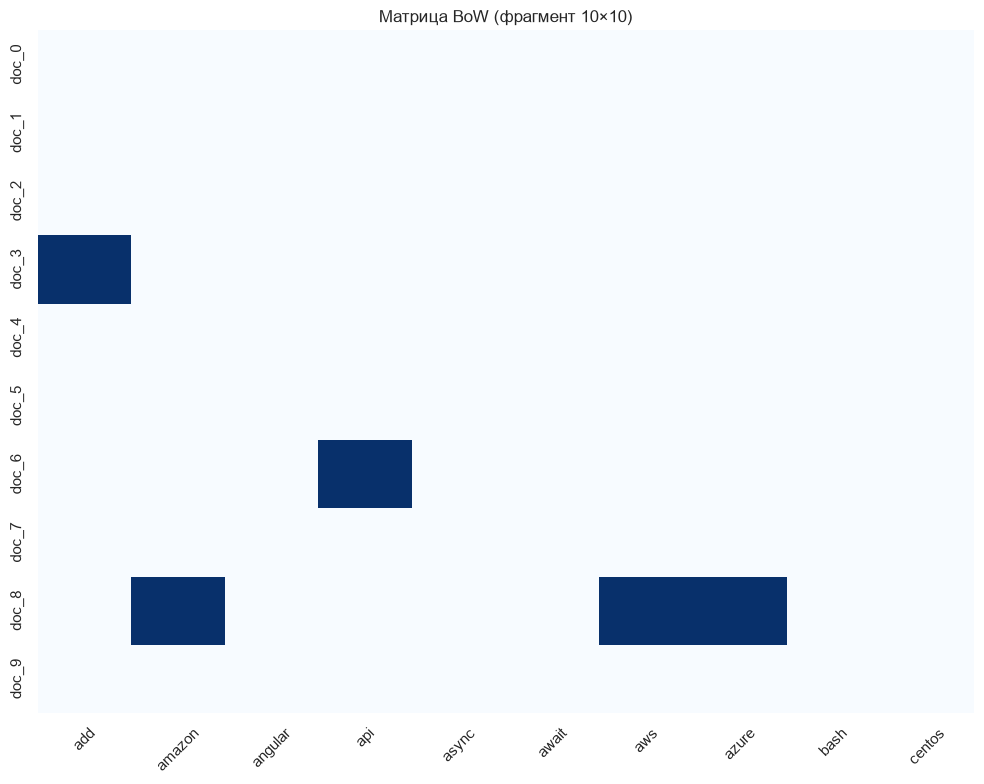

In [173]:
vocabulary = sorted(set(word for tokens in all_tokens for word in tokens))
word2idx = {word: i for i, word in enumerate(vocabulary)}

print(f"Размер словаря: {len(vocabulary)} слов")
print(f"Пример слов: {vocabulary[:10]}")

bow_matrix = []

for tokens in all_tokens:
    vector = [0] * len(vocabulary)
    for word in tokens:
        vector[word2idx[word]] += 1
    bow_matrix.append(vector)

bow_matrix = np.array(bow_matrix)

print(f"\nФорма матрицы BoW: {bow_matrix.shape} (документы x слова)")

plt.figure(figsize=(10, 8))
sns.heatmap(
    bow_matrix[:10, :10], cmap="Blues", cbar=False,
    xticklabels=vocabulary[:10],
    yticklabels=[f"doc_{i}" for i in range(10)])
plt.title("Матрица BoW (фрагмент 10×10)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [174]:
def compute_tf(tokens):
    counts = Counter(tokens)
    total = len(tokens)
    return {word: count / total for word, count in counts.items()}


def compute_idf(all_tokens_list):
    N = len(all_tokens_list)
    df = Counter()

    for tokens in all_tokens_list:
        for word in set(tokens):
            df[word] += 1

    return {word: math.log(N / (1 + count)) for word, count in df.items()}


def compute_tfidf_matrix(all_tokens_list):
    idf = compute_idf(all_tokens_list)
    matrix = []

    for tokens in all_tokens_list:
        tf = compute_tf(tokens)
        vector = [
            tf.get(word, 0) * idf.get(word, 0)
            for word in vocabulary
        ]
        matrix.append(vector)

    return np.array(matrix)


tfidf_matrix = compute_tfidf_matrix(all_tokens)
print(f"Форма матрицы TF-IDF: {tfidf_matrix.shape}")

doc_idx = 0
print(f"\nТоп-5 слов по BoW (документ {doc_idx}):")
bow_scores = bow_matrix[doc_idx]
top_bow = sorted(zip(vocabulary, bow_scores), key=lambda x: -x[1])[:5]
for w, s in top_bow:
    print(f" {w}: {s:.0f}")

print(f"\nТоп-5 слов по TF-IDF (документ {doc_idx}):")
tfidf_scores = tfidf_matrix[doc_idx]
top_tfidf = sorted(zip(vocabulary, tfidf_scores), key=lambda x: -x[1])[:5]
for w, s in top_tfidf:
    print(f" {w}: {s:.4f}")

Форма матрицы TF-IDF: (30, 677)

Топ-5 слов по BoW (документ 0):
 python: 2
 автоматизации: 1
 анализа: 1
 веб: 1
 выбором: 1

Топ-5 слов по TF-IDF (документ 0):
 python: 0.1771
 автоматизации: 0.1042
 анализа: 0.1042
 выбором: 0.1042
 задач: 0.1042


In [175]:
all_texts_processed = [" ".join(tokens) for tokens in all_tokens]

bow_sklearn = CountVectorizer()
bow_sklearn_matrix = bow_sklearn.fit_transform(all_texts_processed).toarray()

print(f"sklearn BoW: {bow_sklearn_matrix.shape}")

tfidf_sklearn = TfidfVectorizer()
tfidf_sklearn_matrix = tfidf_sklearn.fit_transform(all_texts_processed).toarray()

print(f"sklearn TF-IDF: {tfidf_sklearn_matrix.shape}")

print("\nСравнение первых 5 значений TF-IDF:")
print(f" Моя реализация: \n{tfidf_matrix[0, :5]}")
print(f" sklearn: \n{tfidf_sklearn_matrix[0, :5]}")

sklearn BoW: (30, 677)
sklearn TF-IDF: (30, 677)

Сравнение первых 5 значений TF-IDF:
 Моя реализация: 
[0. 0. 0. 0. 0.]
 sklearn: 
[0. 0. 0. 0. 0.]


Топ-10 слов для категории 'Технологии':
  git: 0.0478
  веб: 0.0451
  данных: 0.0435
  python: 0.0349
  javascript: 0.0346
  tcp: 0.0343
  сервис: 0.0341
  слоя: 0.0340
  sql: 0.0337
  обучение: 0.0314

Топ-10 слов для категории 'Кулинария':
  добавьте: 0.0709
  теста: 0.0534
  минут: 0.0522
  яйца: 0.0495
  масло: 0.0399
  соль: 0.0396
  смешайте: 0.0387
  соуса: 0.0358
  нарежьте: 0.0336
  мясо: 0.0335


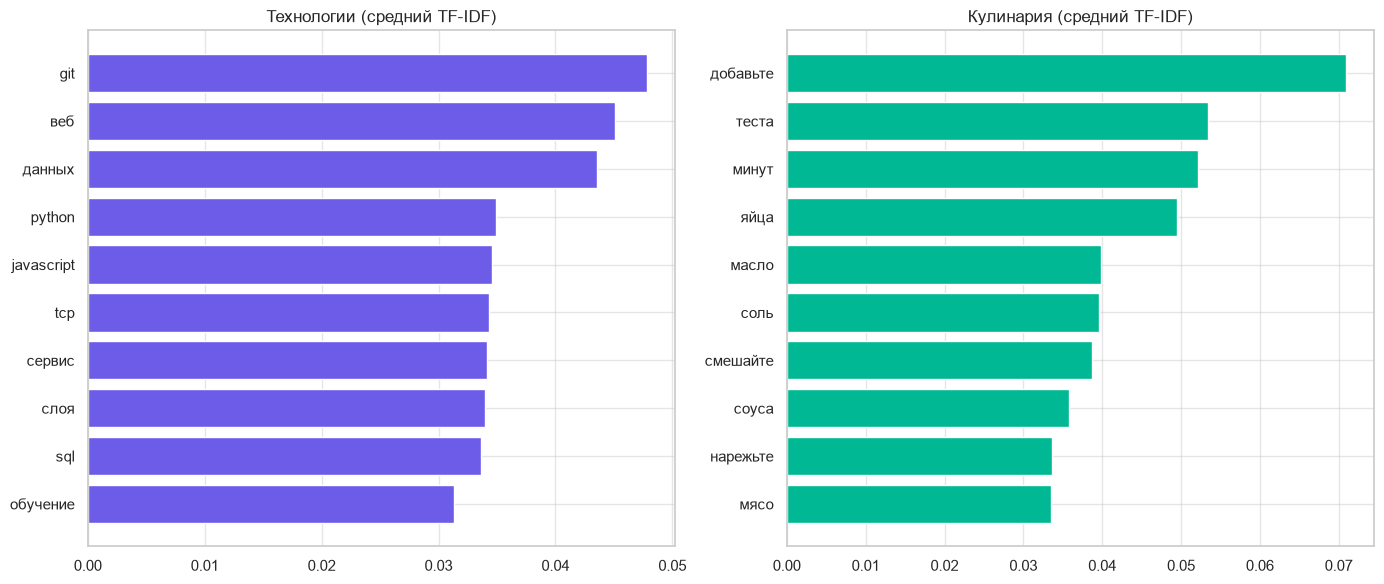

In [176]:
tech_mean_tfidf = tfidf_sklearn_matrix[:15].mean(axis=0)
cook_mean_tfidf = tfidf_sklearn_matrix[15:].mean(axis=0)

vocab_sklearn = tfidf_sklearn.get_feature_names_out()

top_tech = sorted(zip(vocab_sklearn, tech_mean_tfidf), key=lambda x: -x[1])[:10]
print("Топ-10 слов для категории 'Технологии':")
for w, s in top_tech:
    print(f"  {w}: {s:.4f}")

top_cook = sorted(zip(vocab_sklearn, cook_mean_tfidf), key=lambda x: -x[1])[:10]
print("\nТоп-10 слов для категории 'Кулинария':")
for w, s in top_cook:
    print(f"  {w}: {s:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

words_tech, scores_tech = zip(*top_tech)
words_cook, scores_cook = zip(*top_cook)

axes[0].barh(words_tech[::-1], scores_tech[::-1], color="#6c5ce7")
axes[0].set_title("Технологии (средний TF-IDF)")

axes[1].barh(words_cook[::-1], scores_cook[::-1], color="#00b894")
axes[1].set_title("Кулинария (средний TF-IDF)")

plt.tight_layout()
plt.show()

Среднее сходство внутри 'Технологии': 0.0148
Среднее сходство внутри 'Кулинария': 0.0371
Среднее сходство между категориями: 0.0005


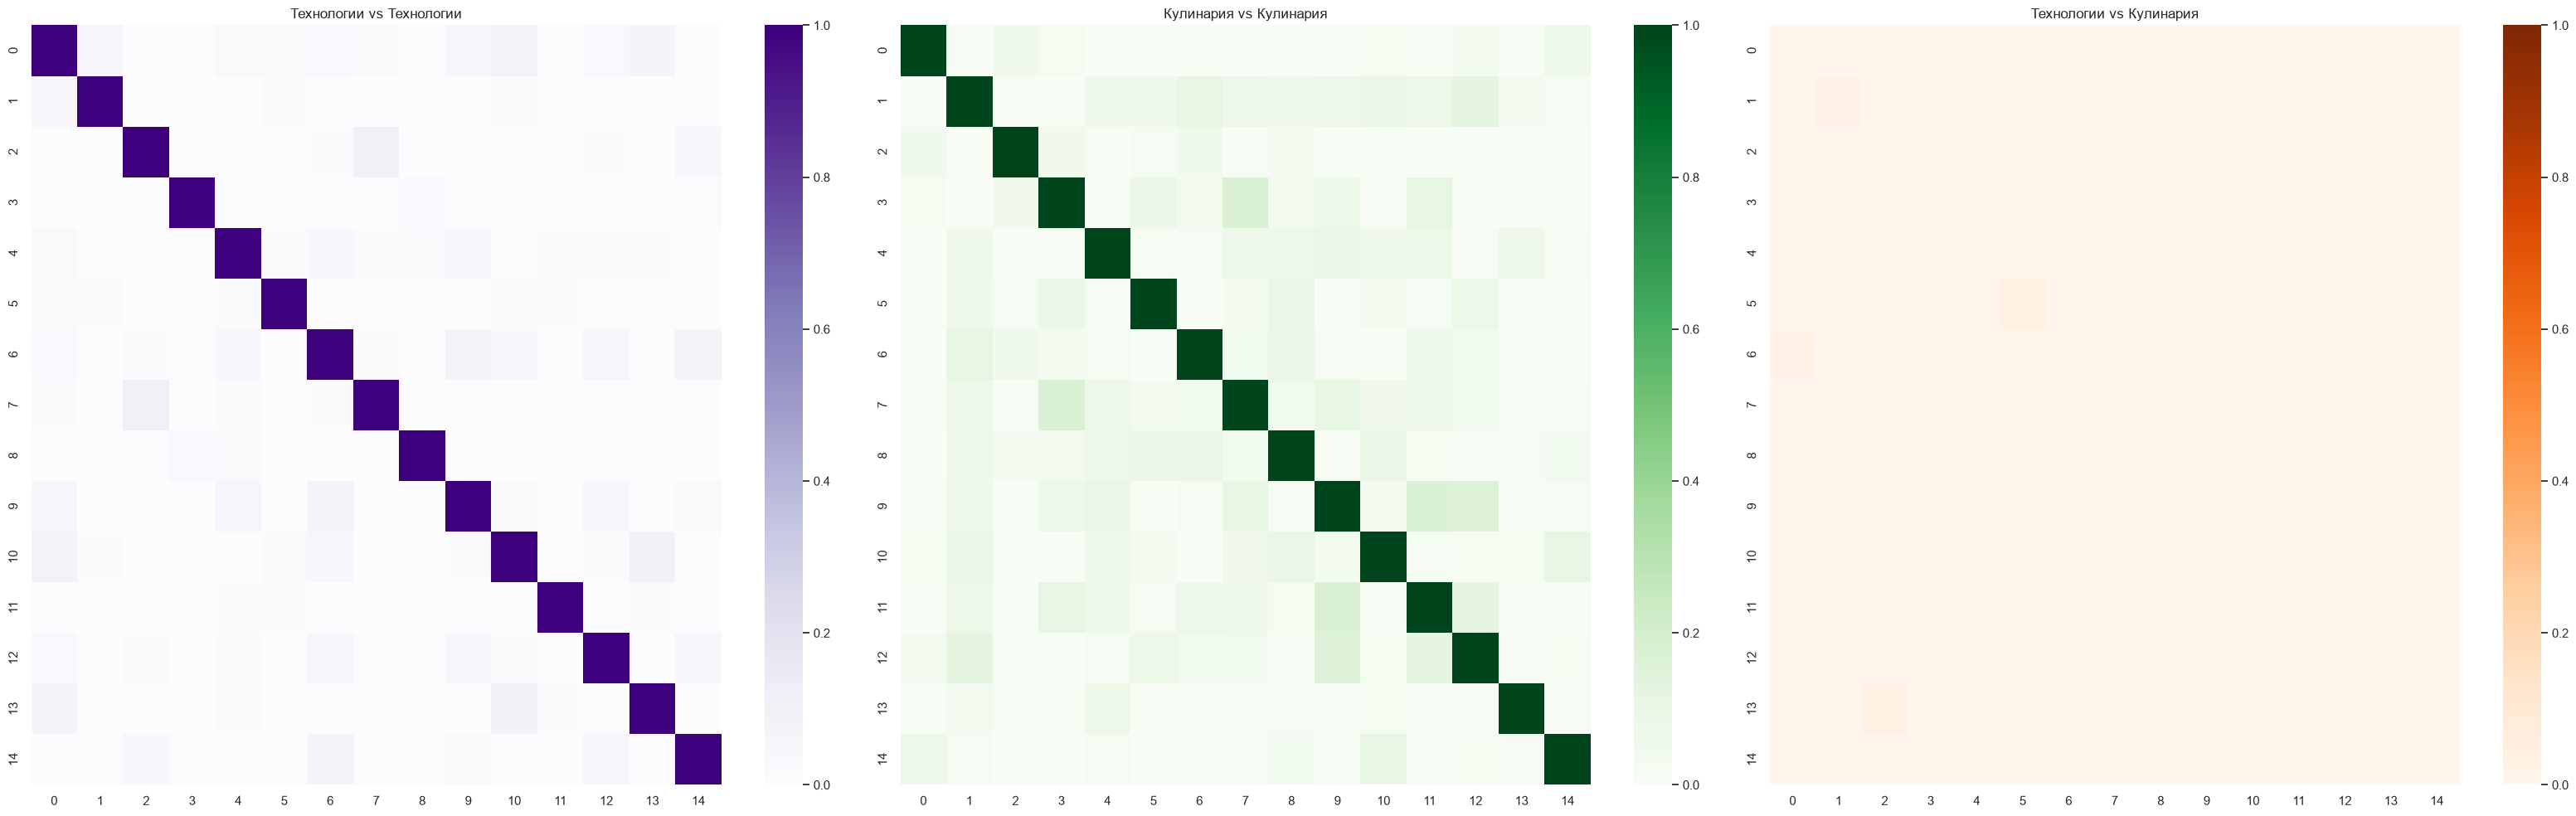

In [177]:
tech_tfidf = tfidf_sklearn_matrix[:15]
cook_tfidf = tfidf_sklearn_matrix[15:]

sim_tech = cosine_similarity(tech_tfidf)
sim_cook = cosine_similarity(cook_tfidf)
sim_cross = cosine_similarity(tech_tfidf, cook_tfidf)

print(f"Среднее сходство внутри 'Технологии': {sim_tech[np.triu_indices(15, k=1)].mean():.4f}")
print(f"Среднее сходство внутри 'Кулинария': {sim_cook[np.triu_indices(15, k=1)].mean():.4f}")
print(f"Среднее сходство между категориями: {sim_cross.mean():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(32, 10))

sns.heatmap(sim_tech, ax=axes[0], cmap="Purples", vmin=0, vmax=1)
axes[0].set_title("Технологии vs Технологии")

sns.heatmap(sim_cook, ax=axes[1], cmap="Greens", vmin=0, vmax=1)
axes[1].set_title("Кулинария vs Кулинария")

sns.heatmap(sim_cross, ax=axes[2], cmap="Oranges", vmin=0, vmax=1)
axes[2].set_title("Технологии vs Кулинария")

plt.tight_layout()
plt.show()

In [178]:
test_tfidf = tfidf_sklearn.transform([" ".join(test_tokens)]).toarray()[0]
similarities = cosine_similarity([test_tfidf], tfidf_sklearn_matrix)[0]

mean_sim_tech = similarities[:15].mean()
mean_sim_cook = similarities[15:].mean()

print(f"Тестовый текст: '{test_text[:60]}...'")
print(f"\nСреднее сходство с 'Технологии': {mean_sim_tech:.4f}")
print(f"Среднее сходство с 'Кулинария': {mean_sim_cook:.4f}")

if mean_sim_cook > mean_sim_tech:
    print("\n🍲 Модель определила текст как: КУЛИНАРИЯ ✅")
else:
    print("\n🔧 Модель определила текст как: ТЕХНОЛОГИИ ❌ (ошибка!)")

top5_idx = np.argsort(similarities)[::-1][:5]
print("\nТоп-5 наиболее похожих документов:")
for i, idx in enumerate(top5_idx, 1):
    cat = "Технологии" if idx < 15 else "Кулинария"
    print(f" {i}. [{cat}] сходство={similarities[idx]:.4f}:{all_texts[idx][:60]}...")

Тестовый текст: 'Сегодня я приготовил вкусный борщ по бабушкиному рецепту. 
С...'

Среднее сходство с 'Технологии': 0.0046
Среднее сходство с 'Кулинария': 0.0506

🍲 Модель определила текст как: КУЛИНАРИЯ ✅

Топ-5 наиболее похожих документов:
 1. [Кулинария] сходство=0.4117:Борщ — традиционное славянское блюдо, которое готовят на мяс...
 2. [Кулинария] сходство=0.1008:Вареники с вишней — любимое блюдо многих. Для теста нужны му...
 3. [Технологии] сходство=0.0695:JavaScript — язык программирования для веб-разработки. Он ра...
 4. [Кулинария] сходство=0.0657:Плов готовят из риса, мяса, моркови и лука в казане. Сначала...
 5. [Кулинария] сходство=0.0484:Для приготовления супа-пюре из тыквы нарежьте тыкву кубиками...


In [179]:
summary = {
    "Метрика": [
        "Размер корпуса (документов)",
        "Размер словаря BoW",
        "Размерность вектора (слов)",
        "Среднее TF-IDF для 'алгоритм' в категории Технологии",
        "Среднее TF-IDF для 'алгоритм' в категории Кулинария",
        "Среднее сходство внутри категории Технологии",
        "Среднее сходство внутри категории Кулинария",
        "Среднее сходство между категориями",
        "Категория тестового текста (предсказание)",
    ],
    "Значение": [
        len(all_texts),
        len(vocab_sklearn),
        tfidf_sklearn_matrix.shape[1],
        tech_mean_tfidf[vocab_sklearn.tolist().index('алгоритм')],
        cook_mean_tfidf[vocab_sklearn.tolist().index('алгоритм')],
        sim_tech[np.triu_indices(15, k=1)].mean(),
        sim_cook[np.triu_indices(15, k=1)].mean(),
        sim_cross.mean(),
        "Кулинария" if mean_sim_cook > mean_sim_tech else "Технологии"
    ]
}

df_summary = pd.DataFrame(summary)
df_summary

,Метрика,Значение
0,Размер корпуса (документов),30
1,Размер словаря BoW,677
2,Размерность вектора (слов),677
3,Среднее TF-IDF для 'алгоритм' в категории Техн...,0.011104
4,Среднее TF-IDF для 'алгоритм' в категории Кули...,0.0
5,Среднее сходство внутри категории Технологии,0.014788
6,Среднее сходство внутри категории Кулинария,0.037092
7,Среднее сходство между категориями,0.00048
8,Категория тестового текста (предсказание),Кулинария
